
# 04 - Baseline Model: Logistic Regression

## Objective
Train a Logistic Regression classifier to establish a baseline for the loan status prediction task.

The workflow includes a stratified train-test split, preprocessing of numerical and categorical features, model training, and evaluation using classification metrics. All preprocessing is fitted on the training data to reduce data leakage.


# Importing libraries

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

importing other necessary tools

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Loading the processed dataset

In [6]:
df = pd.read_csv("/workspaces/loan-approval-prediction/data/processed/loan_data_feature_engineered.csv")

df.head()

,Age,Gender,Education,Person Income,Employee Experience,Home Ownership,Loan Amount,Loan Intent,Credit History,Credit Score,Previous Loan,Loan Status,Loan_to_Income,Log_Person_Income
0,22,female,Master,71948,0,RENT,35000,PERSONAL,3,561,No,1,0.486462,11.183713
1,21,female,High School,12282,0,OWN,1000,EDUCATION,2,504,Yes,0,0.081420,9.415971
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,3,635,No,1,0.442193,9.428592
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,2,675,No,1,0.438855,11.286702
4,24,male,Master,66135,1,RENT,35000,MEDICAL,4,586,No,1,0.529221,11.099469


In [7]:
print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["Loan Status"].value_counts())


Dataset shape: (44988, 14)


,Age,Gender,Education,Person Income,Employee Experience,Home Ownership,Loan Amount,Loan Intent,Credit History,Credit Score,Previous Loan,Loan Status,Loan_to_Income,Log_Person_Income
0,22,female,Master,71948,0,RENT,35000,PERSONAL,3,561,No,1,0.486462,11.183713
1,21,female,High School,12282,0,OWN,1000,EDUCATION,2,504,Yes,0,0.081420,9.415971
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,3,635,No,1,0.442193,9.428592
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,2,675,No,1,0.438855,11.286702
4,24,male,Master,66135,1,RENT,35000,MEDICAL,4,586,No,1,0.529221,11.099469



Missing values: 0
Duplicate rows: 0

Target distribution:


Loan Status
0    34988
1    10000
Name: count, dtype: int64

# defining my variables

In [8]:
target = "Loan Status"

numeric_features = [
    "Age",
    "Employee Experience",
    "Log_Person_Income",
    "Loan Amount",
    "Credit History",
    "Credit Score",
    "Loan_to_Income"
]

categorical_features = [
    "Gender",
    "Education",
    "Home Ownership",
    "Loan Intent",
    "Previous Loan"
]

X = df[numeric_features + categorical_features].copy()
y = df[target].copy()

print("Predictors:", X.shape)
print("Target:", y.shape)

print("\nTarget classes:")
print(y.value_counts(normalize=True).sort_index().round(4))

Predictors: (44988, 12)
Target: (44988,)

Target classes:
Loan Status
0    0.7777
1    0.2223
Name: proportion, dtype: float64


# Spliting data into training and testing data

In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(4))


Training features: (35990, 12)
Testing features: (8998, 12)

Training target proportions:
Loan Status
0    0.7777
1    0.2223
Name: proportion, dtype: float64

Testing target proportions:
Loan Status
0    0.7777
1    0.2223
Name: proportion, dtype: float64


# Build the preprocessing pipeline

1. Numerical features: standardise them using StandardScaler.

2. Categorical features: apply one-hot encoding.

3. Unseen categories: handle them without causing prediction errors.

In [10]:

numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# Training the baseline model:Logistic Regression 

In [12]:

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ]
)

baseline_model.fit(X_train, y_train)

print("Logistic Regression baseline trained successfully!!!")


Logistic Regression baseline trained successfully!!!


I initially used the default class weighting. Because the target is imbalanced, I further examine recall, precision and precision-recall performance rather than relying on accuracy alone.

# Generating predictions

In [13]:

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("First 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities for class 1:")
print(np.round(y_prob[:10], 4))


First 10 predicted classes:
[0 1 0 0 0 0 0 0 0 0]

First 10 predicted probabilities for class 1:
[3.666e-01 8.531e-01 1.000e-04 3.179e-01 2.000e-04 1.000e-04 1.891e-01
 3.000e-04 9.230e-02 2.000e-04]


# Evaluating the model

In [14]:

results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob)
}

baseline_results = pd.DataFrame(
    results.items(),
    columns=["Metric", "Score"]
)

baseline_results["Score"] = baseline_results["Score"].round(4)

display(baseline_results)


,Metric,Score
0,Accuracy,0.8723
1,Precision,0.7267
2,Recall,0.6820
3,F1 Score,0.7036
4,ROC-AUC,0.9357
5,Average Precision,0.8116


### Baseline Model Results

A Logistic Regression model was trained using a stratified 80:20 train-test split. Numerical variables were standardised, while categorical variables were one-hot encoded within a scikit-learn pipeline to prevent preprocessing leakage.

The model achieved an accuracy of 87.23%, precision of 72.67%, recall of 68.20%, and an F1 score of 70.36%. The ROC-AUC was 0.9357, indicating strong discrimination between the two target classes. The average precision score was 0.8116.

Although the model demonstrated strong ranking performance, its recall suggests that some actual class-1 observations were misclassified at the default probability threshold of 0.5. These results provide a benchmark for evaluating more advanced classification models.

# Confusion matrix and classification report

,Predicted 0,Predicted 1
Actual 0,6485,513
Actual 1,636,1364


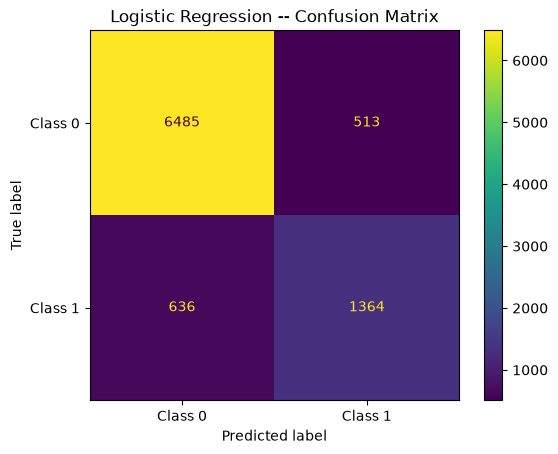

              precision    recall  f1-score   support

           0       0.91      0.93      0.92      6998
           1       0.73      0.68      0.70      2000

    accuracy                           0.87      8998
   macro avg       0.82      0.80      0.81      8998
weighted avg       0.87      0.87      0.87      8998



In [16]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display(
    pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot()
plt.title("Logistic Regression -- Confusion Matrix")
plt.grid(False)
plt.show()

print(classification_report(y_test, y_pred, zero_division=0))


### Logistic Regression Baseline Results

A Logistic Regression classifier was developed as the baseline model using an 80:20 stratified train-test split. Numerical features were standardised, and categorical features were one-hot encoded within a scikit-learn pipeline to prevent data leakage during preprocessing.

The model achieved an accuracy of 87.23% and a weighted F1-score of approximately 0.87. However, performance differed across the target classes. Class 0 achieved a precision of 0.91, recall of 0.93, and F1-score of 0.92. In comparison, class 1 achieved a precision of 0.73, recall of 0.68, and F1-score of 0.70.

These results indicate that the baseline model identifies class 0 more effectively than class 1 at the default classification threshold of 0.5. Although the ROC-AUC of 0.9357 indicates strong discrimination between the classes, the class-specific recall suggests that further evaluation is needed. Logistic Regression will therefore serve as the benchmark against which more advanced classification models are assessed.